# 1_segnet

Bản chuyển từ sample **5. Others/1_segnet.ipynb**. Chạy các ô theo thứ tự.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import math
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset, Subset
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

FULL = False  # True: dùng dữ liệu và số epoch theo sample
PROJECT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "HUONG_DAN.txt").is_file()), Path.cwd())
ROOT = PROJECT / "data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(2018)
torch.set_num_threads(min(4, torch.get_num_threads()))
results = {}

In [2]:
def epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = correct = units = 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            out = model(x)
            if isinstance(criterion, nn.CrossEntropyLoss):
                assert out.argmax(1).shape == y.shape and y.dtype == torch.long
                correct += (out.argmax(1) == y).sum().item()
            else:
                assert out.shape == y.shape
            loss = criterion(out, y)
            if not torch.isfinite(loss):
                raise ValueError("Loss không hữu hạn")
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * y.numel()
            units += y.numel()
    return total_loss / units, correct / units

def fit(name, model, train, valid, criterion, opt, lr, epochs, batch,
        early=False, schedule=False, checkpoint=False, verbose=True):
    for layer in model.modules():
        if isinstance(layer, (nn.Conv2d, nn.Linear)):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    model.to(DEVICE)
    writer = None
    if checkpoint:
        from torch.utils.tensorboard import SummaryWriter
        writer = SummaryWriter("logs/" + name)
    optimizer = opt(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, factor=0.1, patience=4, min_lr=1e-4,
        threshold=1e-4, threshold_mode="abs")
    loaders = [DataLoader(train, batch, shuffle=True), DataLoader(valid, batch)]
    best, stale = float("inf"), 0
    for step in range(1, epochs + 1):
        train_loss, _ = epoch(model, loaders[0], criterion, optimizer)
        val_loss, accuracy = epoch(model, loaders[1], criterion)
        if writer:
            writer.add_scalar("loss/train", train_loss, step)
            writer.add_scalar("loss/validation", val_loss, step)
            writer.add_scalar("accuracy/validation", accuracy, step)
        if val_loss < best:
            best, stale = val_loss, 0
            if checkpoint:
                torch.save(model.state_dict(), f"{name}_best.pt")
        else:
            stale += 1
        if schedule:
            scheduler.step(val_loss)
        if early and stale >= 5:
            break
    if writer:
        writer.close()
    if checkpoint:
        model.load_state_dict(torch.load(f"{name}_best.pt", map_location=DEVICE,
                                         weights_only=True))
        val_loss, accuracy = epoch(model, loaders[1], criterion)
    metric = accuracy if isinstance(criterion, nn.CrossEntropyLoss) else val_loss
    results[name] = (len(train), len(valid), step, val_loss, metric)
    if verbose:
        print(f"{name} | {step} epoch | train loss {train_loss:.5f} | "
              f"val loss {val_loss:.5f}", end="")
        if isinstance(criterion, nn.CrossEntropyLoss):
            print(f" | accuracy {accuracy:.2%}", end="")
        print()
    return model

In [3]:
class HandDepth(Dataset):
    def __init__(self, split):
        self.folder = ROOT / "segnet" / split
        self.files = sorted(p for p in (self.folder / "depth").iterdir() if p.is_file())
        if not self.files:
            raise ValueError(f"Thiếu ảnh trong {self.folder / 'depth'}")
        self.lookup = np.full(256, -1, dtype=np.int64)
        self.lookup[[255, 43, 85, 128, 170, 212, 0]] = np.arange(7)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        image = self.files[i]
        mask = self.folder / "labels" / image.name.replace("depth", "labels")
        def read(path):
            with Image.open(path) as img:
                return np.array(img.resize((96, 96), Image.Resampling.NEAREST),
                                dtype=np.uint8)
        x, gray = read(image), read(mask)
        labels = self.lookup[gray]
        if x.ndim != 2 or labels.ndim != 2 or (labels < 0).any():
            raise ValueError(f"Kiểm tra ảnh xám hoặc mã màu trong {image} và {mask}")
        return torch.from_numpy(x).unsqueeze(0).float(), torch.from_numpy(labels)

def segnet():
    layers = []
    previous = 1
    def append_convs(widths):
        nonlocal previous
        for width in widths:
            layers.extend([nn.Conv2d(previous, width, 3, padding=1),
                           nn.BatchNorm2d(width, eps=1e-3, momentum=0.01), nn.ReLU()])
            previous = width
    for width, depth in [(64, 2), (128, 2), (256, 3), (512, 3), (512, 3)]:
        append_convs([width] * depth)
        layers.append(nn.MaxPool2d(2))
    for widths in [(512, 512, 512), (512, 512, 256), (256, 256, 128), (128, 64), (64,)]:
        layers.append(nn.Upsample(scale_factor=2, mode="nearest"))
        append_convs(widths)
    return nn.Sequential(*layers, nn.Conv2d(64, 7, 1),
                         nn.BatchNorm2d(7, eps=1e-3, momentum=0.01))

Kiểm tra bằng ảnh và mặt nạ giả lập
segnet | 1 epoch | train loss 2.32966 | val loss 1.94595 | accuracy 13.44%


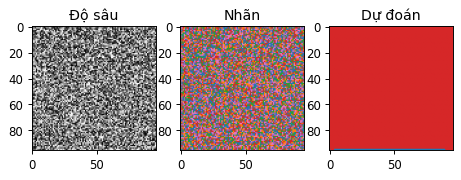

In [4]:
if FULL:
    train, valid = HandDepth("train"), HandDepth("test")
else:
    print("Kiểm tra bằng ảnh và mặt nạ giả lập")
    def mock_masks():
        return TensorDataset(torch.rand(1, 1, 96, 96), torch.randint(7, (1, 96, 96)))
    train, valid = mock_masks(), mock_masks()
model = fit("segnet", segnet(), train, valid, nn.CrossEntropyLoss(), torch.optim.Adam,
            1e-4, 15 if FULL else 1, 8 if FULL else 1)
x, target = valid[0]
with torch.inference_mode():
    mask = model(x[None].to(DEVICE)).argmax(1)[0].cpu()
assert mask.shape == target.shape
fig, axes = plt.subplots(1, 3)
for ax, img, title in zip(axes, [x.squeeze(), target, mask], ["Độ sâu", "Nhãn", "Dự đoán"]):
    ax.imshow(img, cmap="gray" if title == "Độ sâu" else "tab10", **({} if title == "Độ sâu" else {"vmin": 0, "vmax": 9}))
    ax.set_title(title)
plt.show()